In [1]:
from Functions import setup_matplotlib_parameter
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

setup_matplotlib_parameter()

['#0072B2',
 '#E69F00',
 '#009E73',
 '#D55E00',
 '#56B4E9',
 '#CC79A7',
 '#F0E442',
 '#000000']

In [4]:
# Sampling stages in process order (used for the x axis).
STAGE_ORDER = ["S1-DO", "S2-DS", "S3-VT", "S4-CT", "S5-CT", "S6-CT", "S7-CT", "S8-TU"]
ELEMENT_ORDER = ["Al", "O", "S", "Ca"]

# Colors per heat (i-th sorted heat -> HEAT_COLORS[i])
HEAT_COLORS = ["#E69F00", "#56B4E9", "#009E73", "#F0E442",
               "#0072B2", "#D55E00", "#CC79A7", "#000000"]

# Marker per heat (i-th sorted heat -> HEAT_MARKERS[i])
HEAT_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "p"]

# Size correction so all shapes look about equally large (diamonds/squares
# appear bigger than circles and triangles at the same nominal size).
_MARKER_SCALE = {"o": 1.0, "s": 0.85, "^": 1.1, "v": 1.1, "D": 0.8,
                 "P": 1.0, "X": 1.0, "p": 1.0}


def load_data(path: str | Path = "element_data_long.csv") -> pd.DataFrame:
    """Read the long-format CSV and set the stage order as a categorical."""
    df = pd.read_csv(path)
    stages = [s for s in STAGE_ORDER if s in set(df["sample"])]
    extra = sorted(set(df["sample"]) - set(stages))
    df["sample"] = pd.Categorical(df["sample"], categories=stages + extra, ordered=True)
    return df


def summarize(df: pd.DataFrame) -> pd.DataFrame:
    """Mean, standard deviation, min, max and number of heats per element and stage."""
    return (
        df.groupby(["element", "sample"], observed=True)["value"]
        .agg(mean="mean", std="std", min="min", max="max", n="count")
        .reset_index()
    )


def heat_color_map(df: pd.DataFrame, heat_colors=None) -> dict:
    """Map each heat to a color: i-th sorted heat -> ``heat_colors[i]``."""
    heat_colors = HEAT_COLORS if heat_colors is None else heat_colors
    heats = sorted(df["heat"].unique())
    if isinstance(heat_colors, dict):
        return {h: heat_colors[h] for h in heats}
    return {h: heat_colors[i % len(heat_colors)] for i, h in enumerate(heats)}


def heat_marker_map(df: pd.DataFrame, heat_markers=None) -> dict:
    """Map each heat to a marker: i-th sorted heat -> ``heat_markers[i]``."""
    heat_markers = HEAT_MARKERS if heat_markers is None else heat_markers
    heats = sorted(df["heat"].unique())
    if isinstance(heat_markers, dict):
        return {h: heat_markers[h] for h in heats}
    return {h: heat_markers[i % len(heat_markers)] for i, h in enumerate(heats)}


def plot_element(
    df: pd.DataFrame,
    element: str,
    ax: plt.Axes | None = None,
    unit: str = "ppm",
    show_mean: bool = True,
    min_n_for_mean: int = 3,
    jitter: float = 0.12,
    show_heat_labels: bool = False,
    ymin: float | None = 0,
    heat_colors=None,
    heat_markers=None,
    mean_color: str = "0.45",
    markersize: float = 5,
    xtick_rotation: float = 45,
    separators: list[float] | None = None,
    ylabel: bool = True,
    xlabel: bool = True,
) -> plt.Axes:
    """
    Plot one element across all sampling stages.

    Parameters
    ----------
    df : long-format DataFrame from :func:`load_data`.
    element : element symbol as in the ``element`` column, e.g. ``"Al"``.
    ax : existing Axes to draw into; a new figure is created if omitted.
    unit : unit for the y-axis label (adjust if your data isn't ppm).
    show_mean : draw the mean of the heats as a horizontal bar.
    min_n_for_mean : only draw the mean for stages with at least this many
        heats (default 3, i.e. more than 2 measurements).
    jitter : horizontal spread of the heat dots (0 = stacked on the stage).
    show_heat_labels : annotate each dot with its heat number.
    ymin : lower y limit (``None`` lets matplotlib decide).
    heat_colors : colors for the heats, either a list (the i-th sorted heat
        gets ``heat_colors[i]``, same as ``WONG_CYCLE[i]`` in your other plot)
        or a dict ``{heat: color}``. Defaults to :data:`HEAT_COLORS`.
    heat_markers : markers for the heats, list or dict like ``heat_colors``.
        Defaults to :data:`HEAT_MARKERS` (circle, square, triangle, diamond, ...).
    mean_color : any matplotlib color for the mean bar.
    markersize : dot size in points (same meaning as ``markersize`` in ``ax.plot``).
    xtick_rotation : rotation of the stage labels (they collide at 0°).
    separators : x positions for dashed vertical lines between stage groups,
        e.g. ``[2.5]`` to separate S1–S3 from S4–S8.
    ylabel, xlabel : set the per-axes labels (switched off by
        :func:`plot_composition`, which uses shared figure labels instead).
    """
    sub = df[df["element"] == element]
    if sub.empty:
        raise ValueError(f"No data for element {element!r}. "
                         f"Available: {sorted(df['element'].unique())}")

    if ax is None:
        _, ax = plt.subplots()

    stages = list(df["sample"].cat.categories) if hasattr(df["sample"], "cat") else STAGE_ORDER
    xpos = {s: i for i, s in enumerate(stages)}

    colors = heat_color_map(df, heat_colors)
    markers = heat_marker_map(df, heat_markers)
    heats = list(colors)
    # Fixed horizontal offset per heat, so a heat sits at the same spot in every stage.
    offsets = dict(zip(heats, np.linspace(-jitter, jitter, len(heats))
                       if len(heats) > 1 else [0.0]))

    for stage, grp in sub.groupby("sample", observed=True):
        grp = grp.sort_values("heat")
        n = len(grp)
        x = np.array([xpos[stage] + offsets[h] for h in grp["heat"]])

        # One scatter call per heat, because a scatter call takes only one marker.
        for xi, (_, row) in zip(x, grp.iterrows()):
            h = row["heat"]
            m = markers[h]
            ax.scatter(xi, row["value"], s=(markersize * _MARKER_SCALE.get(m, 1.0))**2,
                       marker=m, color=colors[h],
                       edgecolor="white", linewidth=0.6, zorder=3)

        if show_heat_labels:
            for xi, (_, row) in zip(x, grp.iterrows()):
                ax.annotate(str(row["heat"]), (xi, row["value"]),
                            xytext=(4, 2), textcoords="offset points")

        if show_mean and n >= min_n_for_mean:
            half = jitter + 0.1
            ax.hlines(grp["value"].mean(), xpos[stage] - half, xpos[stage] + half,
                      color=mean_color, linewidth=1.6, zorder=2)

    for xs in separators or []:
        ax.axvline(xs, color="0.45", lw=1, ls="--", alpha=0.8, zorder=1)

    ax.set_xticks(range(len(stages)))
    ax.set_xticklabels(stages, rotation=xtick_rotation,
                       ha="right" if xtick_rotation else "center",
                       rotation_mode="anchor")
    ax.set_xlim(-0.6, len(stages) - 0.4)
    if ymin is not None:
        ax.set_ylim(bottom=ymin)
    if xlabel:
        ax.set_xlabel("Sampling stage")
    if ylabel:
        ax.set_ylabel(f"{element} [{unit}]" if unit else element)
    ax.set_title(element)
    return ax


def _legend_handles(colors: dict, markers: dict, show_mean: bool,
                    min_n_for_mean: int, mean_color: str, markersize: float = 5):
    from matplotlib.lines import Line2D

    handles = [Line2D([], [], marker=markers[h], linestyle="", color=c, mec="white",
                      markersize=markersize * _MARKER_SCALE.get(markers[h], 1.0) * 1.2,
                      label=str(h)) for h, c in colors.items()]
    if show_mean:
        handles.append(Line2D([], [], color=mean_color, linewidth=1.6,
                              label=f"Mean (n ≥ {min_n_for_mean})"))
    return handles


def plot_composition(
    df: pd.DataFrame,
    elements: list[str] | None = None,
    unit: str = "ppm",
    ncols: int = 2,
    figsize: tuple[float, float] | None = None,
    sharex: bool = True,
    legend: bool = True,
    panel_labels: bool = True,
    ylabel: str | None = None,
    **kwargs,
):
    """
    Plot several elements as small multiples (one panel per element).

    The panels share one x label ("Sampling stage") and one y label
    (``ylabel``, default ``"Concentration [<unit>]"``); each panel is named by
    its title and carries a letter (a), (b), ... like the inclusion-type plot.

    ``figsize`` defaults to A4 width (210 mm) with ~2.6 in per panel row.
    ``kwargs`` are passed on to :func:`plot_element`, e.g. ``separators=[2.5]``
    or ``show_heat_labels=True``.
    Returns ``(fig, axes)`` where ``axes`` is a flat array of the used Axes.
    """
    import string

    if elements is None:
        present = set(df["element"])
        elements = [e for e in ELEMENT_ORDER if e in present] + sorted(present - set(ELEMENT_ORDER))

    nrows = int(np.ceil(len(elements) / ncols))
    if figsize is None:
        figsize = (210 / 25.4, 2.6 * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=sharex, squeeze=False)
    axes = axes.ravel()

    for k, (ax, el) in enumerate(zip(axes, elements)):
        plot_element(df, el, ax=ax, unit=unit, xlabel=False, ylabel=False, **kwargs)
        if panel_labels:
            ax.text(0.0, 1.02, f"({string.ascii_lowercase[k]})", transform=ax.transAxes,
                    ha="left", va="bottom", fontweight="bold")
    for ax in axes[len(elements):]:
        ax.set_visible(False)

    # With sharex, show stage labels only on the lowest visible panel of each column.
    if sharex:
        for ax in axes[:len(elements)][-ncols:]:
            ax.tick_params(labelbottom=True)

    fig.supxlabel("Sampling stage")
    fig.supylabel(ylabel or (f"Content [{unit}]" if unit else "Content"))

    if legend:
        handles = _legend_handles(
            heat_color_map(df, kwargs.get("heat_colors")),
            heat_marker_map(df, kwargs.get("heat_markers")),
            kwargs.get("show_mean", True),
            kwargs.get("min_n_for_mean", 3),
            kwargs.get("mean_color", "0.45"),
            kwargs.get("markersize", 5),
        )
        # Legend to the right of the panels, as in the inclusion-type plot.
        constrained = type(fig.get_layout_engine()).__name__ == "ConstrainedLayoutEngine"
        if constrained:
            fig.legend(handles=handles, title="Heat", loc="outside right center")
        else:
            fig.tight_layout()
            fig.legend(handles=handles, title="Heat", loc="center left",
                       bbox_to_anchor=(0.98, 0.5))
    elif fig.get_layout_engine() is None:
        fig.tight_layout()
    return fig, axes[:len(elements)]

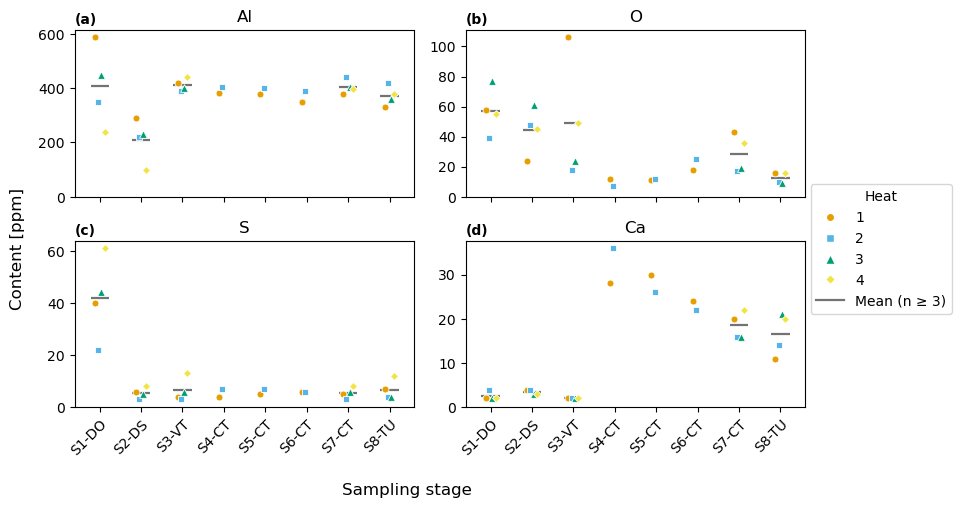

In [5]:
df = load_data("../Data files/Elemental Composition/element_data_long.csv")

fig, axes = plot_composition(df,
                             figsize=(210/25.4, 297/25.4/2.3)
                             )                  # Al, O, S, Ca, one panel each

plt.show()